# 01 · Importación y calidad de datos

**Objetivo:** cargar los datos de Airbnb y de Idealista, limpiarlos y guardarlos en una base de datos SQLite para el resto del proyecto.

**Entradas**
- Inside Airbnb (Madrid, 20/06/2026): `listings` (resumen) y `listings_det` (detalle).
- Precio medio del m² por distrito (Idealista): `datos/brutos/precio_m2_distritos_madrid.csv`.

**Salida:** `datos/intermedios/mercado_inmobiliario.db` con tres tablas relacionadas (`idealista_precio_m2`, `listings`, `listings_det`).

**Contenido**
1. Configuración
2. Carga de datos
3. Calidad de datos · Listings
4. Calidad de datos · Listings detalle
5. Datos externos de Idealista (precio/m²)
6. Generación de la base de datos SQLite

## 1. Configuración

In [ ]:
# Importación de librerías
import os
import sqlite3
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Carga de datos

In [82]:
# Descarga de los dos ficheros de Inside Airbnb (resumen y detalle) a DataFrames de pandas
url_listings = "https://data.insideairbnb.com/spain/comunidad-de-madrid/madrid/2026-06-20/visualisations/listings.csv"
url_listings_det = "https://data.insideairbnb.com/spain/comunidad-de-madrid/madrid/2026-06-20/data/listings.csv.gz"

# Importación de los datos
listings = pd.read_csv(url_listings)
listings_det = pd.read_csv(url_listings_det, compression="gzip")

## 3. Calidad de datos · Listings

### 3.1 Selección de variables

In [84]:
# Se eliminan las variables que no se usarán en el análisis (anfitrión, reseñas y licencia)
a_eliminar = ['host_id', 'host_profile_id', 'host_name', 'number_of_reviews',
       'last_review', 'reviews_per_month', 'calculated_host_listings_count','number_of_reviews_ltm', 'license']

listings=listings.drop(columns=a_eliminar)

### 3.2 Valores nulos

In [85]:
# Recuento de nulos por variable (de mayor a menor)
listings.isna().sum().sort_values(ascending=False)

price                  3538
minimum_nights            2
name                      0
id                        0
neighbourhood_group       0
neighbourhood             0
longitude                 0
latitude                  0
room_type                 0
availability_365          0
dtype: int64

In [86]:
# Se eliminan los anuncios sin precio, ya que no se puede calcular su rentabilidad
listings = listings.dropna(subset='price')

### 3.3 Duplicados

In [87]:
# Verificación de duplicados
listings[listings.duplicated()]
listings.duplicated().sum()
#No se tienen Duplicados en listings

np.int64(0)

### 3.4 Variables categóricas

In [88]:
# Distribución de las variables categóricas
categoricas = listings.select_dtypes(include='object').columns

for col in categoricas:
    print(f"\nVariable: {col}")
    print(listings[col].value_counts())


Variable: name
name
Habitación en piso compartido                       154
Housing Castellana by Sharing Co                     39
Great Studio                                         20
Fantastic residence ``FUNWAY´´ north zone Madrid     18
Habitación piso compartido                           15
                                                   ... 
GuestReady - Modern Studio near Downtown              1
Studio with balcony                                   1
Two bedroom apartment with view                       1
One bedroom superior apartment                        1
Superior Studio                                       1
Name: count, Length: 18009, dtype: int64

Variable: neighbourhood_group
neighbourhood_group
Centro                   8214
Tetuán                   1415
Salamanca                1334
Chamberí                 1261
Arganzuela                926
Retiro                    688
Chamartín                 677
Ciudad Lineal             637
Carabanchel               609
P

C:\Users\USER.ADCYNENC-L024\AppData\Local\Temp\ipykernel_22688\2508484168.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categoricas = listings.select_dtypes(include='object').columns


In [89]:
# Se elimina room_type = 'Hotel room': el objetivo es comprar inmuebles, no hoteles
listings=listings[listings.room_type!='Hotel room']

### 3.5 Variables numéricas

In [90]:
# Estadísticos descriptivos de las variables numéricas
listings.iloc[:,7:10].describe().T

,count,mean,std,min,25%,50%,75%,max
price,19268.0,180.212477,554.279824,3.0,84.0,125.0,184.0,36883.0
minimum_nights,19267.0,6.812737,14.292568,1.0,1.0,2.0,4.0,365.0
availability_365,19268.0,222.578680,110.634335,0.0,125.0,247.0,324.0,365.0


**Precio:** tiene valores atípicos tanto en el mínimo como en el máximo, así que se analiza su distribución.

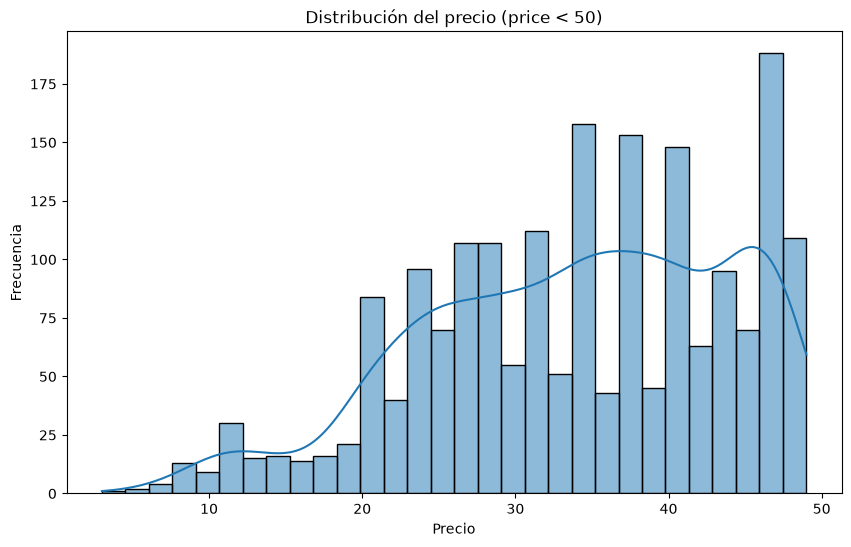

In [91]:
# Distribución del precio por debajo de 50 €
plt.figure(figsize=(10,6))
sns.histplot(listings[listings.price<50].price, bins=30, kde=True)
plt.title('Distribución del precio (price < 50)')
plt.xlabel('Precio')
plt.ylabel('Frecuencia');

In [92]:
# Se conserva el rango de precios de 20 a 1.000 € para evitar que los valores atípicos distorsionen el análisis
listings=listings[listings.price.between(20,1000)]
listings.price.describe().T

count    18962.000000
mean       152.886984
std        116.185310
min         20.000000
25%         85.000000
50%        125.000000
75%        183.000000
max       1000.000000
Name: price, dtype: float64

## 4. Calidad de datos · Listings detalle

### 4.1 Selección de variables

In [94]:
# Se conservan solo las variables necesarias del fichero de detalle
a_incluir = ['id',
             'description',
             'accommodates',
             'bathrooms',
             'bedrooms',
             'beds',
             'estimated_occupancy_l365d',
             'estimated_revenue_l365d',
             'review_scores_location'
            ]
listings_det=listings_det[a_incluir]

In [96]:
# estimated_revenue_l365d es el producto de otras dos variables que ya existen (precio por noche × ocupación), por lo que se elimina
listings_det=listings_det.drop(columns='estimated_revenue_l365d')

### 4.2 Filtrado de registros

In [97]:
# Se eliminan los registros con ocupación estimada = 0: la ocupación es imprescindible para calcular la rentabilidad
listings_det=listings_det[listings_det.estimated_occupancy_l365d!=0]

In [98]:
# Revisión de nulos
listings_det.isna().sum()

id                              0
description                   494
accommodates                    0
bathrooms                    1963
bedrooms                     3480
beds                         1482
estimated_occupancy_l365d       0
review_scores_location          1
dtype: int64

In [99]:
# Valores atípicos en accommodates: se conservan anuncios de hasta 8 personas
listings_det.accommodates.value_counts()
# Nos quedamos con valores de ocupantes hasta 8
listings_det=listings_det[listings_det.accommodates<=8]

In [100]:
# Máximo 5 baños
listings_det=listings_det[listings_det.bathrooms<=5]

In [101]:
# Máximo 5 habitaciones
listings_det=listings_det[listings_det.bedrooms<=5]

In [102]:
# Máximo 6 camas
listings_det=listings_det[listings_det.beds<=6]

### 4.3 Nulos y duplicados tras el filtrado

In [103]:
# Revisión de nulos tras el filtrado de atípicos (el filtrado ha eliminado los nulos)
listings_det.isna().sum()

id                             0
description                  288
accommodates                   0
bathrooms                      0
bedrooms                       0
beds                           0
estimated_occupancy_l365d      0
review_scores_location         1
dtype: int64

In [105]:
# Los nulos de habitaciones, baños y camas servirán para estimar el precio de compra del inmueble.
# Si hubiera quedado alguno, se imputaría por proxy con esta tabla cruzada (camas → habitaciones)
pd.crosstab(listings_det.beds,listings_det.bedrooms)
# con la variable de n de camas podemos estimar el numero de habitaciones

bedrooms,1.0,2.0,3.0,4.0,5.0
beds,,,,,
1.0,3554,48,15,9,7
2.0,2429,1168,10,2,0
3.0,319,1148,387,1,0
4.0,76,456,337,81,0
5.0,14,72,151,40,11
6.0,7,22,43,23,1


In [106]:
# Verificación de duplicados
listings_det.duplicated().sum()

np.int64(0)

## 5. Datos externos de Idealista (precio/m²)

Se usa el precio medio del m² por distrito como aproximación (proxy) del coste de compra de cada inmueble.

In [107]:
# Carga del precio/m² por distrito y ajuste de la columna (escala y descuento)
df_idealista = pd.read_csv("../datos/brutos/precio_m2_distritos_madrid.csv")
df_idealista['precio_m2_sep_2026']=df_idealista.precio_m2_sep_2026/10-0.2
df_idealista=df_idealista.loc[1:21]

In [108]:
# Se igualan los nombres de distrito de Idealista a los de Airbnb (neighbourhood_group)
equivalencias = {
    'Barrio de Salamanca': 'Salamanca',
    'Fuencarral': 'Fuencarral - El Pardo',
    'Moncloa': 'Moncloa - Aravaca',
    'San Blas': 'San Blas - Canillejas',
}

df_idealista['distrito'] = df_idealista['distrito'].replace(equivalencias)

# Verificación
print("Sin coincidencia en listings:", set(df_idealista['distrito']) - set(listings['neighbourhood_group']))
print("En listings y no en idealista:", set(listings['neighbourhood_group']) - set(df_idealista['distrito']))

Sin coincidencia en listings: set()
En listings y no en idealista: set()


In [110]:
# Validación del cruce listings + precio/m² por distrito (solo comprobación, no se guarda)
Merge_listings = listings.merge(
    df_idealista,
    how='left',
    left_on='neighbourhood_group',
    right_on='distrito',
).drop(columns='distrito')

# Verificación
print(Merge_listings.shape)
print("Nulos en precio_m2_sep_2026:", Merge_listings['precio_m2_sep_2026'].isna().sum())
listings.head()

(18962, 11)
Nulos en precio_m2_sep_2026: 0


,id,name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,availability_365
0,1008521039996399925,Alojamiento tranquilo,Carabanchel,Opañel,40.387990,-3.72470,Private room,42.0,1.0,268
1,887679074200493161,Hermoso para disfrutar Madrid,Puente de Vallecas,Palomeras Sureste,40.385482,-3.64084,Entire home/apt,210.0,1.0,364
5,1542083092059647802,Double standard room I Akeah Gran Vía,Centro,Universidad,40.424880,-3.70733,Private room,259.0,1.0,150
8,1558001589553082984,Double Superior Room,Arganzuela,Acacias,40.402480,-3.71151,Private room,113.0,1.0,209
9,1537650273057726639,"NH Madrid Paseo De La Habana, Standard Room",Chamartín,Hispanoamérica,40.455600,-3.68195,Private room,151.0,1.0,240


## 6. Generación de la base de datos SQLite

Se crean tres tablas relacionadas por clave primaria y foránea, se cargan los datos limpios y se verifica el número de filas y la integridad referencial.

In [111]:
# Creación del esquema, carga de las tres tablas y verificaciones
ruta_db = Path("../datos/intermedios/mercado_inmobiliario.db")
ruta_db.parent.mkdir(parents=True, exist_ok=True)

esquema = """
DROP TABLE IF EXISTS listings_det;
DROP TABLE IF EXISTS listings;
DROP TABLE IF EXISTS idealista_precio_m2;

CREATE TABLE idealista_precio_m2 (
    distrito            TEXT PRIMARY KEY,
    precio_m2_sep_2026  REAL
);

CREATE TABLE listings (
    id                  INTEGER PRIMARY KEY,
    name                TEXT,
    neighbourhood_group TEXT,
    neighbourhood       TEXT,
    latitude            REAL,
    longitude           REAL,
    room_type           TEXT,
    price               REAL,
    minimum_nights      REAL,
    availability_365    INTEGER,
    FOREIGN KEY (neighbourhood_group) REFERENCES idealista_precio_m2 (distrito)
);

CREATE TABLE listings_det (
    id                         INTEGER PRIMARY KEY,
    description                TEXT,
    accommodates               INTEGER,
    bathrooms                  REAL,
    bedrooms                   REAL,
    beds                       REAL,
    estimated_occupancy_l365d  INTEGER,
    review_scores_location     REAL,
    FOREIGN KEY (id) REFERENCES listings (id)
);
"""

# Orden de carga: primero la tabla padre (idealista), luego listings y por último listings_det
tablas = {
    'idealista_precio_m2': df_idealista,
    'listings': listings,
    'listings_det': listings_det,
}

with sqlite3.connect(ruta_db) as conn:
    conn.executescript(esquema)

    for nombre, df in tablas.items():
        df.to_sql(nombre, conn, if_exists='append', index=False)

    # Verificación de filas
    for nombre in tablas:
        n = pd.read_sql(f"SELECT COUNT(*) AS filas FROM {nombre}", conn).iloc[0, 0]
        print(f"{nombre}: {n} filas")

    # Verificación de integridad referencial (filas huérfanas)
    print(pd.read_sql("PRAGMA foreign_key_check", conn).groupby('table').size())

idealista_precio_m2: 21 filas
listings: 18962 filas
listings_det: 10431 filas
table
listings_det    195
dtype: int64
